# Laboppgave 2: Shazam

**Lab 2, PHYS116**  
**Navn:** Rapport lab2  
**Dato:** [13.09.2026]

## Import og hjelpefunksjoner

In [17]:
import os
import pickle
import sounddevice as sd
from scipy.io import wavfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp, spectrogram
from IPython.display import Markdown, display

# Laste Library_wav
def load_library(folder):
    songs = []
    for name in sorted(os.listdir(folder)):
        if name.endswith(".wav"):
            path = os.path.join(folder, name)
            fs, signal = wavfile.read(path)
            songs.append((fs, signal))
    return songs

# Lagre database
def save_database(database, path):
    with open(path, "wb") as f:
        pickle.dump(database, f)

# Laste database
def load_database(path):
    with open(path, "rb") as f:
        database = pickle.load(f)
    return database

# Test med mikrofon
def record_audio(fs, time):
    print("Recording...")
    audio = sd.rec(
    int(time * fs),
    samplerate=fs,
    channels=1,
    dtype="float32")
    sd.wait()
    print("Done recording")
    return audio.flatten()

def run_microphone_query(fs, time, database, L_window, L_overlap,
top_fraction, fan_out):
    audio = record_audio(fs, time)
    song_id, score = match_query(audio, fs, database, L_window,
    L_overlap, top_fraction, fan_out)
    if song_id is not None:
        filename = f"song_{song_id:03d}.wav"
        print("Match:", filename)
        print("Score:", score)
    else:
        print("No match found")


## Oppgave 4.1:

Vi beregner et spektrogram med Hann-vindu og beholder en bestemt andel av de
sterkeste frekvensbinnene i hver tidsramme. De valgte punktene tegnes over
spektrogrammet. Her betyr topper de sterkeste binnene, ikke nødvendigvis
separate lokale maksimum.

### Felles funksjoner

`Sxx` inneholder effekttettheten, slik at `strength = spectrum` kan brukes direkte.
`int(len(spectrum) * top_fraction)` gir antallet bin som beholdes i hver ramme,
avrundet ned til nærmeste heltall.

In [18]:
def pick_peaks(Sxx, tt, f, top_fraction):
    """
    Finner de sterkeste frekvensbinnene i hver tidsramme
    Args:
    Sxx (array-like): Spektrogram (n_frequencies, n_frames)
    tt (array-like): Tidspunkt for hver ramme
    f (array-like): Frekvensene i spektrogrammet
    top_fraction (float): Andelen frekvenser som beholdes
    Returns:
    peak_tt (list): Tidspunktene til toppene
    peak_freqs (list): Frekvensene til toppene
    """
    peak_tt = []
    peak_freqs = []
    # Loop over tid
    for t in range(Sxx.shape[1]):
        # Spekteret ved dette tidspunktet
        spectrum = Sxx[:, t]
        # Styrken til hvert frekvensbin
        strength = spectrum
        # Finn sterkeste frekvenser
        idx = np.argsort(strength)[::-1]
        n_keep = int(len(spectrum) * top_fraction)
        strong_idx = idx[:n_keep]
        # Lag peaks
        for f_idx in strong_idx:
            peak_tt.append(tt[t])
            peak_freqs.append(f[f_idx])
    return peak_tt, peak_freqs

In [19]:
def plot_spectrogram(f_axis, tt, Sxx, peak_tt, peak_freqs, title):
    """Tegn spektrogrammet med de valgte frekvensbinnene som punkter."""
    # Relativ dB-skala gjør både sterke og svakere komponenter synlige.
    Sxx_db = 10 * np.log10(np.maximum(Sxx / np.max(Sxx), 1e-12))

    fig, ax = plt.subplots(figsize=(11, 4.8))
    mesh = ax.pcolormesh(
        tt, f_axis, Sxx_db, shading="auto", cmap="magma",
        vmin=-70, vmax=0,
    )
    ax.scatter(
        peak_tt, peak_freqs, s=14, color="cyan",
        edgecolors="black", linewidths=0.25,
        label="Valgte frekvensbin", zorder=3,
    )
    ax.set_xlabel("Tid [s]")
    ax.set_ylabel("Frekvens [Hz]")
    ax.set_ylim(0, f_axis[-1])
    ax.set_title(title)
    ax.legend(loc="upper left")
    fig.colorbar(mesh, ax=ax, label="Effekttetthet [dB relativt maksimum]")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

### 4.1 a

Spektrogrammet beregnes med vinduslengde 1024 og overlapp 512 sampler.

In [20]:
fs = 8000
T = 2.0
t = np.arange(0, T, 1 / fs)
L_window = 1024
L_overlap = 512

x1 = 1.00 * chirp(t, f0=500, f1=1500, t1=T, method="linear")
x2 = 0.99 * chirp(t, f0=2500, f1=3500, t1=T, method="linear")
x = x1 + x2

f_axis, tt, Sxx = spectrogram(
    x, fs=fs, window="hann", nperseg=L_window,
    noverlap=L_overlap, scaling="density",
)

print(f"Antall frekvensbin: {Sxx.shape[0]}")
print(f"Antall tidsrammer: {Sxx.shape[1]}")
print(f"Avstand mellom frekvensbin: {fs / L_window:.4f} Hz")
print(f"Avstand mellom tidsrammer: {(L_window - L_overlap) / fs:.3f} s")

Antall frekvensbin: 513
Antall tidsrammer: 30
Avstand mellom frekvensbin: 7.8125 Hz
Avstand mellom tidsrammer: 0.064 s


top_fraction = 0.002: 1 bin per ramme, 30 punkter totalt


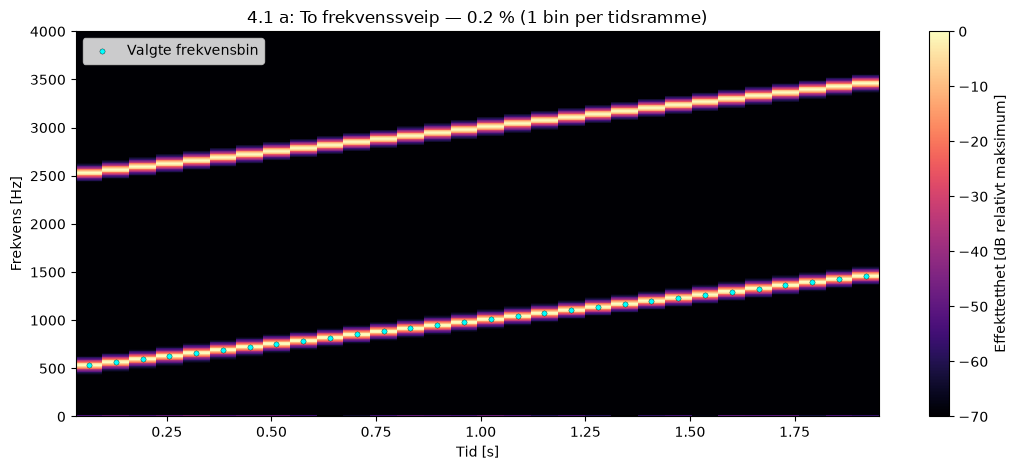

top_fraction = 0.004: 2 bin per ramme, 60 punkter totalt


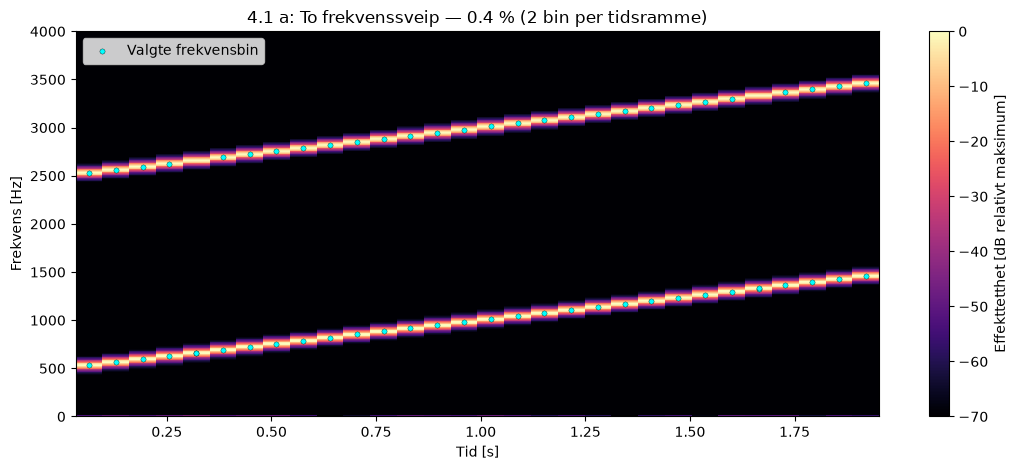

In [21]:
resultater_a = []

for top_fraction in (0.002, 0.004):
    peak_tt, peak_freqs = pick_peaks(Sxx, tt, f_axis, top_fraction)
    n_keep = int(len(f_axis) * top_fraction)
    peak_freqs_array = np.asarray(peak_freqs)
    resultater_a.append({
        "top_fraction": top_fraction,
        "n_keep": n_keep,
        "n_peaks": len(peak_tt),
        "lavt_sveip": int(np.sum(peak_freqs_array < 2000)),
        "hoyt_sveip": int(np.sum(peak_freqs_array > 2000)),
    })

    print(f"top_fraction = {top_fraction}: {n_keep} bin per ramme, "
          f"{len(peak_tt)} punkter totalt")
    plot_spectrogram(
        f_axis, tt, Sxx, peak_tt, peak_freqs,
        f"4.1 a: To frekvenssveip — {100 * top_fraction:.1f} % "
        f"({n_keep} bin per tidsramme)",
    )

* Hvor mange frekvensbin inneholder spektrogrammet?  
Det inneholder (1024/2 + 1 = 513) frekvensbin.

* Hvor mange beholdes per tidsramme?  
Ved top_fraction = 0.002: int(513 × 0.002) = 1 bin.
Ved top_fraction = 0.004: int(513 × 0.004) = 2 bin.

* Hvorfor følger punktene først bare det sterkeste frekvenssveipet?  
Når bare ett bin beholdes, velges det med størst effekttetthet. Sveipet med amplitude 1,00 er litt sterkere enn sveipet med amplitude 0,99, og punktene følger derfor dette.

### 4.1 b:

Vi velger song_009.wav og bruker hele lydfilen. Spektrogrammet beregnes med
Hann-vindu, vinduslengde 1024 og overlapp 512 sampler. De 0,2 % sterkeste
frekvensbinnene markeres, altså ett bin per tidsramme med dette oppsettet.

Lydfil: song_009.wav
Samplingsfrekvens: 8000 Hz
Varighet: 132.15 s
Frekvensbin: 513
Tidsrammer: 2063
Beholdte bin per ramme: 1
Antall markerte punkter: 2063


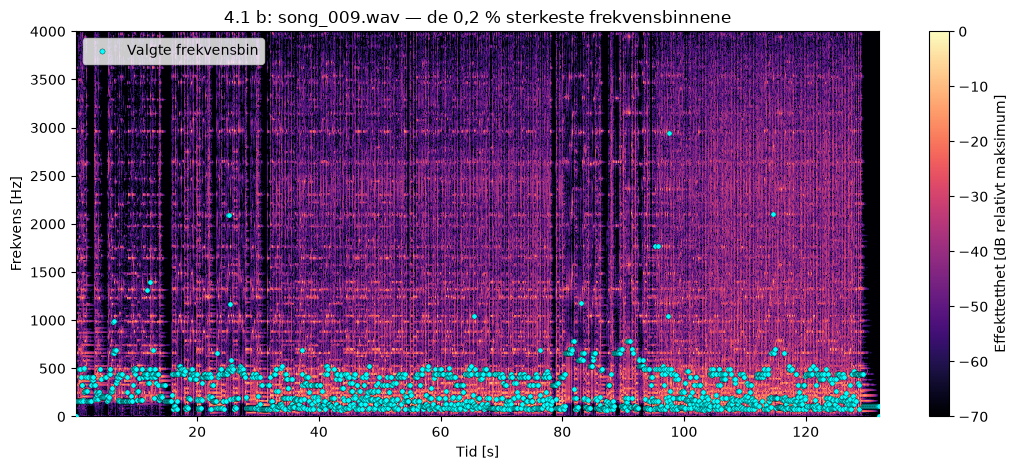

In [22]:
# Last inn sangene med hjelpefunksjonen fra starten av notebooken.
library_folder = Path("library_wav")
songs = load_library(library_folder)
song_path = library_folder / "song_009.wav"

# Bruk samme sortering som load_library for å finne riktig sang.
song_names = sorted(name for name in os.listdir(library_folder) if name.endswith(".wav"))
song_index = song_names.index(song_path.name)
fs_song, audio = songs[song_index]

# Bruker float unngår heltallsaritmetikk. Stereo gjøres om til mono.
x_song = audio.astype(float)
if x_song.ndim == 2:
    x_song = x_song.mean(axis=1)
if np.issubdtype(audio.dtype, np.integer):
    x_song /= max(abs(np.iinfo(audio.dtype).min), np.iinfo(audio.dtype).max)

f_song, tt_song, Sxx_song = spectrogram(
    x_song, fs=fs_song, window="hann", nperseg=L_window,
    noverlap=L_overlap, scaling="density",
)
peaks_song = pick_peaks(Sxx_song, tt_song, f_song, top_fraction=0.002)

print(f"Lydfil: {song_path.name}")
print(f"Samplingsfrekvens: {fs_song} Hz")
print(f"Varighet: {len(x_song) / fs_song:.2f} s")
print(f"Frekvensbin: {len(f_song)}")
print(f"Tidsrammer: {len(tt_song)}")
print(f"Beholdte bin per ramme: {int(len(f_song) * 0.002)}")
print(f"Antall markerte punkter: {len(peaks_song[0])}")

plot_spectrogram(
    f_song, tt_song, Sxx_song, *peaks_song,
    title=f"4.1 b: {song_path.name} — de 0,2 % sterkeste frekvensbinnene",
)

In [23]:
display(Markdown(
    f"**Resultat:** Lydfilen har samplingsfrekvens {fs_song} Hz og varighet "
    f"{len(x_song) / fs_song:.2f} s. Spektrogrammet inneholder "
    f"{Sxx_song.shape[0]} frekvensbin og {Sxx_song.shape[1]} tidsrammer. "
    f"Med `top_fraction = 0.002` beholdes ett bin per ramme, som gir "
    f"**{len(peaks_song[0])} markerte punkter**. Punktene viser hvilken "
    "frekvens som har størst effekttetthet i hver ramme. De følger derfor "
    "ikke nødvendigvis sangens melodi; for eksempel kan bass eller en "
    "sterk overtone dominere."
))

**Resultat:** Lydfilen har samplingsfrekvens 8000 Hz og varighet 132.15 s. Spektrogrammet inneholder 513 frekvensbin og 2063 tidsrammer. Med `top_fraction = 0.002` beholdes ett bin per ramme, som gir **2063 markerte punkter**. Punktene viser hvilken frekvens som har størst effekttetthet i hver ramme. De følger derfor ikke nødvendigvis sangens melodi; for eksempel kan bass eller en sterk overtone dominere.